# PCA portfolios: 90-day walk-forward experiment

**Question:** Can PCA estimated from past returns help construct a portfolio with better future risk/return characteristics?

This starter tests **risk-based allocation**, not a directional return forecast. It compares PCA minimum variance, sample-covariance minimum variance, and equal weighting.

- Training: trailing **252 trading-day returns**, fitted again before every test.
- Holding: **90 calendar days**, with scheduled boundaries moved to the next available trading date.
- Timing: train through the trading day before entry; buy at the entry close.
- Positions: long-only, maximum 10% per stock; buy and hold within each interval.
- Each interval is a standalone experiment: fully buy at entry and liquidate at exit. Charge both sides. This is intentionally simpler than trading only the differences between portfolios.
- Only complete intervals are tested. Compounded results reinvest the proceeds at the next boundary.

**Limitations:** The editable stock list below is selected today, not reconstructed historically. Results are a retrospective demonstration with survivorship/selection bias. Historical adjusted prices can be revised. This is exploratory development, not an untouched final holdout. No stock list or parameter setting is claimed to be optimal.


## 1. Imports and settings

Run the install line below if packages are missing, then restart the kernel. The default dates match the original project's general period, with extra history for training.

Change `HOLD_CALENDAR_DAYS` to change the test horizon. It does **not** change the training window. Ninety trading days would be a different experiment.


In [12]:
# Uncomment if needed:
# %pip install numpy pandas matplotlib scipy scikit-learn yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.decomposition import PCA
from IPython.display import display

TICKERS = [
    "AAPL", "MSFT", "AMZN", "GOOGL", "JPM", "BAC", "JNJ", "UNH",
    "PG", "KO", "WMT", "HD", "XOM", "CVX", "CAT", "HON",
    "NEE", "DUK", "DIS", "VZ",
]
DOWNLOAD_START = "2020-01-01"
DOWNLOAD_END = "2026-01-01"  # Exclusive.
TEST_START = "2022-01-03"
TRAIN_DAYS = 252
HOLD_CALENDAR_DAYS = 90
VARIANCE_TARGET = 0.80
MAX_WEIGHT = 0.10
COST_BPS = 10  # Per dollar bought OR sold.
INITIAL_CAPITAL = 10_000.0
CSV_PATH = None  # Optional daily adjusted-close CSV: date index, ticker columns.

assert TRAIN_DAYS >= 2 and HOLD_CALENDAR_DAYS > 0
assert 0 < VARIANCE_TARGET <= 1 and 0 < MAX_WEIGHT <= 1
assert 0 <= COST_BPS < 10_000
assert len(TICKERS) == len(set(TICKERS))
assert len(TICKERS) * MAX_WEIGHT >= 1


## 2. Load daily adjusted prices

Use a saved adjusted-close CSV or download with `yfinance`. With `auto_adjust=True`, the downloaded `Close` is adjusted. Do not add dividends again.

We retain incomplete columns here. Eligibility is decided from each training window alone. An unavailable price during a held position stops the backtest instead of silently removing the stock or filling its return with zero.


In [13]:
if CSV_PATH is not None:
    prices = pd.read_csv(CSV_PATH, index_col=0, parse_dates=True)
else:
    try:
        import yfinance as yf
    except ImportError as exc:
        raise ImportError("Install yfinance using the commented %pip line, or set CSV_PATH.") from exc
    raw = yf.download(
        TICKERS, start=DOWNLOAD_START, end=DOWNLOAD_END,
        interval="1d", auto_adjust=True, progress=False,
    )
    if raw is None or raw.empty:
        raise RuntimeError("No prices downloaded. Check the connection and ticker symbols.")
    prices = raw["Close"].copy()
    if isinstance(prices, pd.Series):
        prices = prices.to_frame(TICKERS[0])

prices.index = pd.DatetimeIndex(pd.to_datetime(prices.index)).tz_localize(None)
prices = prices.sort_index().reindex(columns=TICKERS).astype(float)
prices = prices.loc[
    (prices.index >= pd.Timestamp(DOWNLOAD_START))
    & (prices.index < pd.Timestamp(DOWNLOAD_END))
]
if prices.empty or prices.index.has_duplicates:
    raise ValueError("Prices must have a nonempty, unique daily date index.")
if not np.isfinite(prices.to_numpy()[prices.notna().to_numpy()]).all():
    raise ValueError("Found infinite prices.")
if (prices <= 0).any().any():
    raise ValueError("Adjusted prices must be positive.")
if prices.isna().all(axis=1).any():
    raise ValueError("A supplied date has no prices; inspect the data instead of silently dropping it.")

display(pd.DataFrame({
    "observed_prices": prices.count(),
    "missing_prices": prices.isna().sum(),
}))
print(f"Dates: {prices.index.min().date()} through {prices.index.max().date()}")
print("No full-period stock filtering has been applied.")


,observed_prices,missing_prices
Ticker,,
AAPL,1508,0
MSFT,1508,0
AMZN,1508,0
GOOGL,1508,0
JPM,1508,0
BAC,1508,0
JNJ,1508,0
UNH,1508,0
PG,1508,0


Dates: 2020-01-02 through 2025-12-31
No full-period stock filtering has been applied.


## 3. Portfolio construction

PCA retains enough components to reach the training variance target. Its covariance estimate is:

**retained component covariance + diagonal residual variances.**

The residual term preserves individual stock risk. Both optimized portfolios minimize estimated variance with identical constraints. The optimizer's objective is scaled for numerical stability; scaling does not change the solution. Failure raises an error rather than silently replacing a strategy.


In [14]:
def minimum_variance_weights(covariance, max_weight):
    n = covariance.shape[0]
    if n * max_weight < 1 - 1e-10:
        raise ValueError("Too few eligible stocks for the weight cap.")
    scale = np.trace(covariance) / n
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("Invalid covariance scale.")
    matrix = covariance / scale
    result = minimize(
        fun=lambda w: w @ matrix @ w,
        jac=lambda w: 2 * matrix @ w,
        x0=np.full(n, 1 / n),
        method="SLSQP",
        bounds=[(0.0, max_weight)] * n,
        constraints=[{
            "type": "eq",
            "fun": lambda w: w.sum() - 1,
            "jac": lambda w: np.ones(n),
        }],
        options={"ftol": 1e-10, "maxiter": 1000},
    )
    if not result.success:
        raise RuntimeError(f"Optimization failed: {result.message}")
    w = result.x
    if abs(w.sum() - 1) > 1e-7 or w.min() < -1e-8 or w.max() > max_weight + 1e-7:
        raise RuntimeError("Optimizer returned invalid weights.")
    w = np.maximum(w, 0)
    return w / w.sum()


def fit_portfolios(history, train_days, variance_target, max_weight):
    # Only historical prices are accepted by this function.
    window = history.tail(train_days + 1)
    if len(window) != train_days + 1:
        raise ValueError("Not enough training history. Move TEST_START later.")
    eligible = window.columns[window.notna().all()]
    returns = window[eligible].pct_change(fill_method=None).iloc[1:]
    returns = returns.loc[:, returns.var(ddof=1) > 1e-12]
    if returns.shape[1] * max_weight < 1 - 1e-10:
        raise ValueError("Too few complete, nonconstant stocks in this training window.")

    sample_cov = returns.cov().to_numpy()
    pca = PCA(svd_solver="full").fit(returns)
    cumulative = np.cumsum(pca.explained_variance_ratio_)
    k = min(int(np.searchsorted(cumulative, variance_target)) + 1, len(cumulative))
    directions = pca.components_[:k].T
    common_cov = (directions * pca.explained_variance_[:k]) @ directions.T
    residual = np.maximum(np.diag(sample_cov - common_cov), 0)
    pca_cov = common_cov + np.diag(residual)

    # Tiny, fixed numerical ridge applied to BOTH estimates.
    ridge = 1e-8 * np.trace(sample_cov) / len(sample_cov)
    identity = np.eye(len(sample_cov))
    weights = pd.DataFrame({
        "PCA": minimum_variance_weights(pca_cov + ridge * identity, max_weight),
        "Sample covariance": minimum_variance_weights(sample_cov + ridge * identity, max_weight),
        "Equal weight": np.full(returns.shape[1], 1 / returns.shape[1]),
    }, index=returns.columns)
    info = {
        "train_start": window.index[0],
        "train_end": window.index[-1],
        "train_returns": len(returns),
        "stocks": returns.shape[1],
        "components": k,
        "explained_variance": cumulative[k - 1],
        "excluded": ", ".join(history.columns.difference(returns.columns)),
    }
    return weights, info


## 4. Schedule and buy-and-hold accounting

Scheduled boundaries are spaced 90 calendar days apart, anchored to `TEST_START`. Each boundary maps to the first available trading date on or after it, so actual spans can vary slightly.

For weights w and adjusted prices P, gross portfolio value within an interval is the sum of **w × P(date)/P(entry)**. This naturally allows weights to drift.

With a per-dollar cost c, buying uses capital/(1+c); liquidating returns proceeds×(1-c). We report market volatility excluding these one-time fee jumps, plus the net interval return including both fees.


In [ ]:
def make_boundaries(index, test_start, hold_days):
    scheduled = pd.date_range(
        pd.Timestamp(test_start), index[-1], freq=f"{hold_days}D"
    )
    positions = index.searchsorted(scheduled)
    valid = positions < len(index)
    schedule = pd.DataFrame({
        "scheduled": scheduled[valid],
        "execution": index[positions[valid]],
    }).drop_duplicates("execution")
    if len(schedule) < 2:
        raise ValueError("Not enough data for one complete holding interval.")
    return schedule.reset_index(drop=True)


def evaluate_hold(held_prices, weights, cost_bps):
    if len(held_prices) < 2 or held_prices.isna().any().any():
        raise ValueError("Missing held prices or an empty interval. Inspect the data.")
    relative_prices = held_prices / held_prices.iloc[0]
    gross_value = relative_prices.to_numpy() @ weights.to_numpy()
    market_returns = gross_value[1:] / gross_value[:-1] - 1
    cost = cost_bps / 10_000
    net_value = gross_value / (1 + cost)
    net_value[-1] *= 1 - cost  # Liquidate at the final close.
    with_initial_cash = np.r_[1.0, net_value]
    drawdowns = with_initial_cash / np.maximum.accumulate(with_initial_cash) - 1
    return {
        "gross_return": gross_value[-1] - 1,
        "net_return": net_value[-1] - 1,
        "annualized_volatility": np.std(market_returns, ddof=1) * np.sqrt(252),
        "interval_max_drawdown": drawdowns.min(),
    }


def run_backtest(price_data, test_start, train_days, hold_days, variance_target, max_weight, cost_bps):
    schedule = make_boundaries(price_data.index, test_start, hold_days)
    records, audits, allocations = [], [], {}
    for interval in range(len(schedule) - 1):
        entry = schedule.loc[interval, "execution"]
        exit_date = schedule.loc[interval + 1, "execution"]
        # Strictly earlier prices: entry-day returns cannot affect weights.
        history = price_data.loc[price_data.index < entry]
        weights, info = fit_portfolios(history, train_days, variance_target, max_weight)
        held = price_data.loc[entry:exit_date, weights.index]
        if held.isna().any().any():
            missing = held.columns[held.isna().any()].tolist()
            raise ValueError(f"Missing holding-period prices for {missing}, starting {entry.date()}.")
        assert info["train_end"] < entry < exit_date
        allocations[entry] = weights
        audits.append({
            "entry": entry, "exit": exit_date,
            "calendar_days": (exit_date - entry).days,
            "holding_returns": len(held) - 1,
            **info,
        })
        for strategy in weights.columns:
            records.append({
                "entry": entry, "exit": exit_date, "strategy": strategy,
                **evaluate_hold(held, weights[strategy], cost_bps),
            })
    return pd.DataFrame(records), pd.DataFrame(audits), allocations


## 5. Run the historical tests

All three strategies use identical training dates, eligible stocks, holding intervals, and fees. Inspect excluded stocks and dates before interpreting performance.

This loop uses the next block only to measure outcomes. It does not use those outcomes to choose the portfolio for that block.


In [16]:
results, audit, allocations = run_backtest(
    prices, TEST_START, TRAIN_DAYS, HOLD_CALENDAR_DAYS,
    VARIANCE_TARGET, MAX_WEIGHT, COST_BPS,
)
display(audit)
net_returns = results.pivot(index="exit", columns="strategy", values="net_return")
display(net_returns.style.format("{:.2%}"))
print(f"Completed {len(audit)} intervals; incomplete final interval excluded.")


,entry,exit,calendar_days,holding_returns,train_start,train_end,train_returns,stocks,components,explained_variance,excluded
0,2022-01-03,2022-04-04,91,63,2020-12-31,2021-12-31,252,20,8,0.822276,
1,2022-04-04,2022-07-05,92,62,2021-04-05,2022-04-01,252,20,7,0.803063,
2,2022-07-05,2022-09-30,87,62,2021-07-01,2022-07-01,252,20,7,0.825896,
3,2022-09-30,2022-12-29,90,62,2021-09-29,2022-09-29,252,20,7,0.828548,
4,2022-12-29,2023-03-29,90,61,2021-12-28,2022-12-28,252,20,6,0.814530,
5,2023-03-29,2023-06-27,90,61,2022-03-25,2023-03-28,252,20,6,0.817324,
6,2023-06-27,2023-09-25,90,62,2022-06-23,2023-06-26,252,20,6,0.800269,
7,2023-09-25,2023-12-26,92,64,2022-09-21,2023-09-22,252,20,7,0.803751,
8,2023-12-26,2024-03-25,90,61,2022-12-21,2023-12-22,252,20,9,0.824482,
9,2024-03-25,2024-06-21,88,61,2023-03-22,2024-03-22,252,20,9,0.812647,


strategy,Equal weight,PCA,Sample covariance
exit,,,
2022-04-04 00:00:00,0.64%,-0.98%,-0.17%
2022-07-05 00:00:00,-12.16%,-10.31%,-9.67%
2022-09-30 00:00:00,-5.65%,-7.38%,-7.15%
2022-12-29 00:00:00,11.16%,14.78%,15.40%
2023-03-29 00:00:00,-0.76%,-5.71%,-5.96%
2023-06-27 00:00:00,5.47%,1.62%,1.83%
2023-09-25 00:00:00,0.90%,1.89%,1.60%
2023-12-26 00:00:00,6.04%,2.88%,2.81%
2024-03-25 00:00:00,8.11%,6.99%,6.20%


Completed 16 intervals; incomplete final interval excluded.


### S&P 500 comparison (SPY)

Use **SPY adjusted prices** as an investable S&P 500 proxy, including dividend adjustments. SPY tracks the index but includes fund expenses and tracking differences; this is not the raw S&P 500 price index. [Fund description](https://www.ssga.com/us/en/individual/etfs/state-street-spdr-sp-500-etf-trust-spy).

The benchmark uses exactly the portfolio entry/exit dates, starting capital, and entry/exit fees for every interval. Like the portfolios, it is liquidated and repurchased at each boundary, rather than continuously held without intermediate trades. It is used only for comparison, never added to the PCA stock universe.

If using a CSV, include an adjusted-close `SPY` column in the same file. Missing benchmark dates raise an error instead of changing the comparison period.


In [17]:
BENCHMARK_TICKER = "SPY"
BENCHMARK_LABEL = "S&P 500 proxy (SPY)"

if CSV_PATH is not None:
    benchmark_table = pd.read_csv(CSV_PATH, index_col=0, parse_dates=True)
    if BENCHMARK_TICKER not in benchmark_table.columns:
        raise ValueError("Add a daily adjusted-close SPY column to your CSV for the S&P 500 comparison.")
    benchmark_prices = benchmark_table[BENCHMARK_TICKER].copy()
else:
    import yfinance as yf
    benchmark_raw = yf.download(
        BENCHMARK_TICKER,
        start=audit.iloc[0]["entry"].strftime("%Y-%m-%d"),
        end=(audit.iloc[-1]["exit"] + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
        interval="1d", auto_adjust=True, progress=False,
    )
    if benchmark_raw is None or benchmark_raw.empty:
        raise RuntimeError("No SPY prices downloaded. Retry before comparing results.")
    benchmark_prices = benchmark_raw["Close"].copy()
    if isinstance(benchmark_prices, pd.DataFrame):
        benchmark_prices = benchmark_prices[BENCHMARK_TICKER]

benchmark_prices.index = pd.DatetimeIndex(pd.to_datetime(benchmark_prices.index)).tz_localize(None)
benchmark_prices = benchmark_prices.sort_index().astype(float)
if benchmark_prices.index.has_duplicates:
    raise ValueError("Duplicate dates in SPY prices.")
benchmark_records = []
for interval in audit.itertuples(index=False):
    holding_dates = prices.loc[interval.entry:interval.exit].index
    held_benchmark = benchmark_prices.reindex(holding_dates).to_frame(BENCHMARK_TICKER)
    if not np.isfinite(held_benchmark.to_numpy()).all() or (held_benchmark <= 0).any().any():
        raise ValueError(f"Missing or invalid SPY prices in interval starting {interval.entry.date()}.")
    benchmark_records.append({
        "entry": interval.entry, "exit": interval.exit,
        "strategy": BENCHMARK_LABEL,
        **evaluate_hold(held_benchmark, pd.Series({BENCHMARK_TICKER: 1.0}), COST_BPS),
    })

# Keep the original strategy results separate, so rerunning does not duplicate SPY.
benchmark_results = pd.DataFrame(benchmark_records)
comparison_results = pd.concat([results, benchmark_results], ignore_index=True)
comparison_returns = comparison_results.pivot(index="exit", columns="strategy", values="net_return")
assert comparison_returns.index.equals(net_returns.index)
assert comparison_returns.notna().all().all()
display(comparison_returns.style.format("{:.2%}"))


strategy,Equal weight,PCA,S&P 500 proxy (SPY),Sample covariance
exit,,,,
2022-04-04 00:00:00,0.64%,-0.98%,-4.27%,-0.17%
2022-07-05 00:00:00,-12.16%,-10.31%,-16.19%,-9.67%
2022-09-30 00:00:00,-5.65%,-7.38%,-6.29%,-7.15%
2022-12-29 00:00:00,11.16%,14.78%,7.63%,15.40%
2023-03-29 00:00:00,-0.76%,-5.71%,4.86%,-5.96%
2023-06-27 00:00:00,5.47%,1.62%,8.86%,1.83%
2023-09-25 00:00:00,0.90%,1.89%,-0.75%,1.60%
2023-12-26 00:00:00,6.04%,2.88%,10.27%,2.81%
2024-03-25 00:00:00,8.11%,6.99%,9.40%,6.20%


## 6. Compare results

Primary question: does PCA reduce subsequent volatility? Also inspect net returns and drawdowns. Beating equal weighting alone does not establish that PCA adds value: compare with sample covariance too.

The curve below shows wealth **at completed interval boundaries**, not daily wealth. The summary drawdown is the worst separately measured within-interval drawdown; it is not a full-backtest drawdown. No Sharpe ratio is reported without a defined risk-free series.

The dashed black line is the S&P 500 proxy (SPY), normalized to the same starting capital and charged the same interval trading costs. SPY is also included in the performance table and interval-return bars.


,total_net_return,annualized_net_return,mean_interval_volatility,worst_within_interval_drawdown,positive_interval_fraction
strategy,,,,,
Equal weight,46.14%,10.09%,13.33%,-15.21%,75.00%
PCA,34.93%,7.88%,11.82%,-15.70%,75.00%
S&P 500 proxy (SPY),45.47%,9.96%,16.76%,-19.82%,68.75%
Sample covariance,34.09%,7.71%,11.75%,-15.27%,68.75%


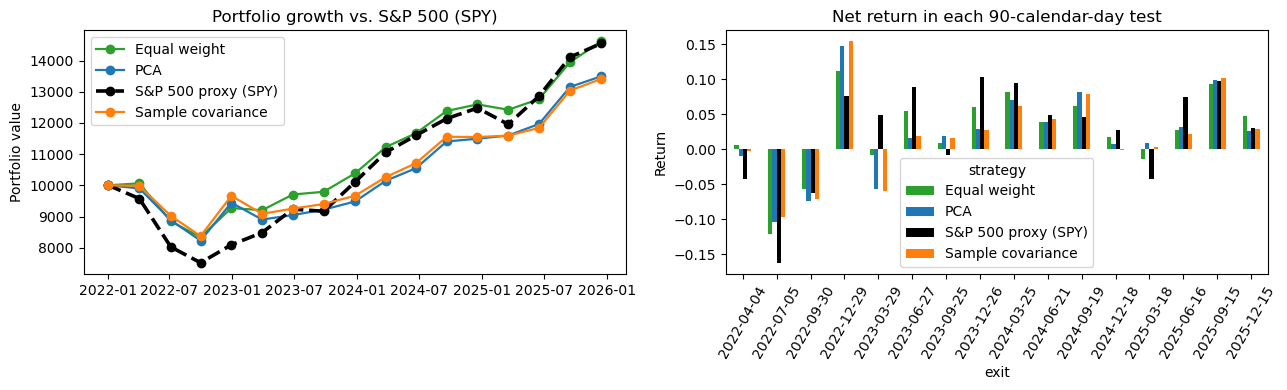

Fraction of intervals in which PCA had:
  lower volatility than equal weight: 93.8%
  lower volatility than sample covariance: 31.2%
  higher net return than equal weight: 50.0%


,PCA,Sample covariance,Equal weight
Ticker,,,
KO,10.00%,10.00%,5.00%
DUK,10.00%,10.00%,5.00%
JPM,10.00%,10.00%,5.00%
AMZN,10.00%,10.00%,5.00%
WMT,10.00%,10.00%,5.00%
PG,10.00%,10.00%,5.00%
JNJ,10.00%,10.00%,5.00%
VZ,10.00%,10.00%,5.00%
MSFT,7.98%,7.41%,5.00%


  higher net return than SPY: 43.8%
  lower volatility than SPY: 100.0%


In [18]:
ending_growth = (1 + comparison_returns).cumprod()
years = (audit.iloc[-1]["exit"] - audit.iloc[0]["entry"]).days / 365.25
summary = pd.DataFrame({
    "total_net_return": ending_growth.iloc[-1] - 1,
    "annualized_net_return": ending_growth.iloc[-1] ** (1 / years) - 1,
    "mean_interval_volatility": comparison_results.groupby("strategy")["annualized_volatility"].mean(),
    "worst_within_interval_drawdown": comparison_results.groupby("strategy")["interval_max_drawdown"].min(),
    "positive_interval_fraction": (comparison_returns > 0).mean(),
})
display(summary.style.format("{:.2%}"))

initial_row = pd.DataFrame(
    1.0, index=pd.DatetimeIndex([audit.iloc[0]["entry"]]), columns=ending_growth.columns
)
boundary_wealth = pd.concat([initial_row, ending_growth]) * INITIAL_CAPITAL
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_colors = {
    "PCA": "tab:blue", "Sample covariance": "tab:orange",
    "Equal weight": "tab:green", BENCHMARK_LABEL: "black",
}
for strategy in boundary_wealth.columns:
    axes[0].plot(
        boundary_wealth.index, boundary_wealth[strategy], label=strategy,
        color=plot_colors[strategy], marker="o",
        linewidth=2.6 if strategy == BENCHMARK_LABEL else 1.6,
        linestyle="--" if strategy == BENCHMARK_LABEL else "-",
    )
axes[0].legend()
axes[0].set(title="Portfolio growth vs. S&P 500 (SPY)", ylabel="Portfolio value")
comparison_returns.plot.bar(ax=axes[1], color=[plot_colors[s] for s in comparison_returns.columns])
axes[1].set(title="Net return in each 90-calendar-day test", ylabel="Return")
axes[1].set_xticklabels([d.strftime("%Y-%m-%d") for d in comparison_returns.index], rotation=60)
plt.tight_layout()
plt.show()

volatility = comparison_results.pivot(index="exit", columns="strategy", values="annualized_volatility")
print("Fraction of intervals in which PCA had:")
print(f"  lower volatility than equal weight: {(volatility['PCA'] < volatility['Equal weight']).mean():.1%}")
print(f"  lower volatility than sample covariance: {(volatility['PCA'] < volatility['Sample covariance']).mean():.1%}")
print(f"  higher net return than equal weight: {(comparison_returns['PCA'] > comparison_returns['Equal weight']).mean():.1%}")
display(allocations[audit.iloc[0]["entry"]].sort_values("PCA", ascending=False).style.format("{:.2%}"))

print(f"  higher net return than SPY: {(comparison_returns['PCA'] > comparison_returns[BENCHMARK_LABEL]).mean():.1%}")
print(f"  lower volatility than SPY: {(volatility['PCA'] < volatility[BENCHMARK_LABEL]).mean():.1%}")


## 7. Check timing and weights

These checks should pass before interpreting an equity curve. The last check deliberately changes every price from the first entry onward and verifies the first allocation remains unchanged.


In [19]:
assert (audit["train_end"] < audit["entry"]).all()
assert (audit["exit"] > audit["entry"]).all()
assert (audit["train_returns"] == TRAIN_DAYS).all()
for weights in allocations.values():
    assert np.allclose(weights.sum(), 1)
    assert weights.min().min() >= -1e-8
    assert weights.max().max() <= MAX_WEIGHT + 1e-7

first_entry = audit.iloc[0]["entry"]
changed_future = prices.copy()
changed_future.loc[changed_future.index >= first_entry] *= np.linspace(0.5, 2, prices.shape[1])
unchanged_weights, _ = fit_portfolios(
    changed_future.loc[changed_future.index < first_entry],
    TRAIN_DAYS, VARIANCE_TARGET, MAX_WEIGHT,
)
pd.testing.assert_frame_equal(allocations[first_entry], unchanged_weights)
print("Timing, training-length, weight, and future-data invariance checks passed.")


Timing, training-length, weight, and future-data invariance checks passed.


## 8. Write your conclusion before adding complexity

- Did PCA lower future volatility relative to **both** benchmarks?
- What happened to returns and drawdowns after costs?
- Was improvement consistent across intervals or driven by one period?
- How many components did each fit retain?
- What changes if you use a different training window or cost assumption?
- Which conclusions are weakened by the selected stock universe and short history?

Choose a small number of alternatives during development and freeze them before a genuinely unexamined evaluation period. Do not choose the best settings from these results and call the same dates an untouched test.

Next steps could include historical constituent data, trading only allocation changes, a daily continuous portfolio ledger, or a separate return-forecasting model using PCA features.

References: [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [SLSQP optimizer](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-slsqp.html), [yfinance download implementation](https://github.com/ranaroussi/yfinance/blob/main/yfinance/multi.py), [backtesting biases](https://portfoliooptimizationbook.com/book/8.2-seven-sins.html).
